In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
# Pip install method (recommended)

!pip install ultralytics

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.4/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

## Custom Training

In [ ]:
# OPTIONAL: run this once at the start of a fresh session to avoid train-2, train-3, ... naming.
# Ultralytics auto-increments the run folder name whenever runs/detect/train already exists,
# instead of overwriting it. Clearing old runs here means training will save cleanly to
# runs/detect/train (not train-2) every time you start over.
import shutil

if os.path.exists(f"{HOME}/runs"):
    shutil.rmtree(f"{HOME}/runs")
    print("Cleared old runs/ directory.")
else:
    print("No previous runs/ directory found.")


No previous runs/ directory found.


**Note:** the cell below contains your Roboflow API key in plaintext. If you share, publish, or push this notebook (e.g. as a paper appendix or to GitHub), that key will leak. Consider rotating it in your Roboflow account settings and loading it with `from getpass import getpass; api_key = getpass()` instead of hardcoding it.

In [ ]:
import os  # set ROBOFLOW_API_KEY in the Colab secrets or environment; never paste a key here
!mkdir {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
project = rf.workspace("md-rakibul-hasan-nishat").project("object-hkkvs")
version = project.version(1)
dataset = version.download("yolov12")




/content/datasets
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.6/324.6 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 1.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to object-1 in yolov12:: 100%|██████████| 387/387 [00:00<00:00, 8868.81it/s]


In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo12s.pt data=/content/datasets/object-1/data.yaml epochs=100 imgsz=640 plots=True

/content
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/object-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset

## Model Validation & Evaluation Metrics

After training, run explicit validation on the trained weights. This regenerates (or generates for the first time, if `plots=True` wasn't fully captured during training) all the standard YOLO/Ultralytics evaluation artifacts needed for a paper: confusion matrix, F1/P/R/PR curves, and per-class + overall mAP.

In [ ]:
%cd {HOME}
# Path to the data.yaml generated by Roboflow (same path used in training above)
DATA_YAML = "/content/datasets/object-1/data.yaml"

# Load the best weights saved during training
best_model = YOLO(f"{HOME}/runs/detect/train/weights/best.pt")

# Run validation on the test split -> saves confusion_matrix.png, F1_curve.png,
# P_curve.png, R_curve.png, PR_curve.png, and val_batch predictions to runs/detect/val
metrics = best_model.val(data=DATA_YAML, split="test", plots=True, save_json=True)

/content
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12s summary (fused): 159 layers, 9,231,267 parameters, 0 gradients, 23.2 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 12.3±7.0 MB/s, size: 34.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/object-1/test/labels... 19 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19 260.5it/s 0.1s
val: New cache created: /content/datasets/object-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1it/s 1.8s
                   all         19         35          1      0.914      0.983       0.72
Speed: 14.9ms preprocess, 39.4ms inference, 0.0ms loss, 2.3ms postprocess per image
Saving /content/runs/detect/val/predictions.json...

Evaluating faster-coco-eval mAP...


### Training Curves (Loss & Metrics vs. Epoch)

Ultralytics automatically saves `results.png` (box/cls/dfl loss, precision, recall, mAP50, mAP50-95 over all epochs) and `results.csv` to the training run directory.

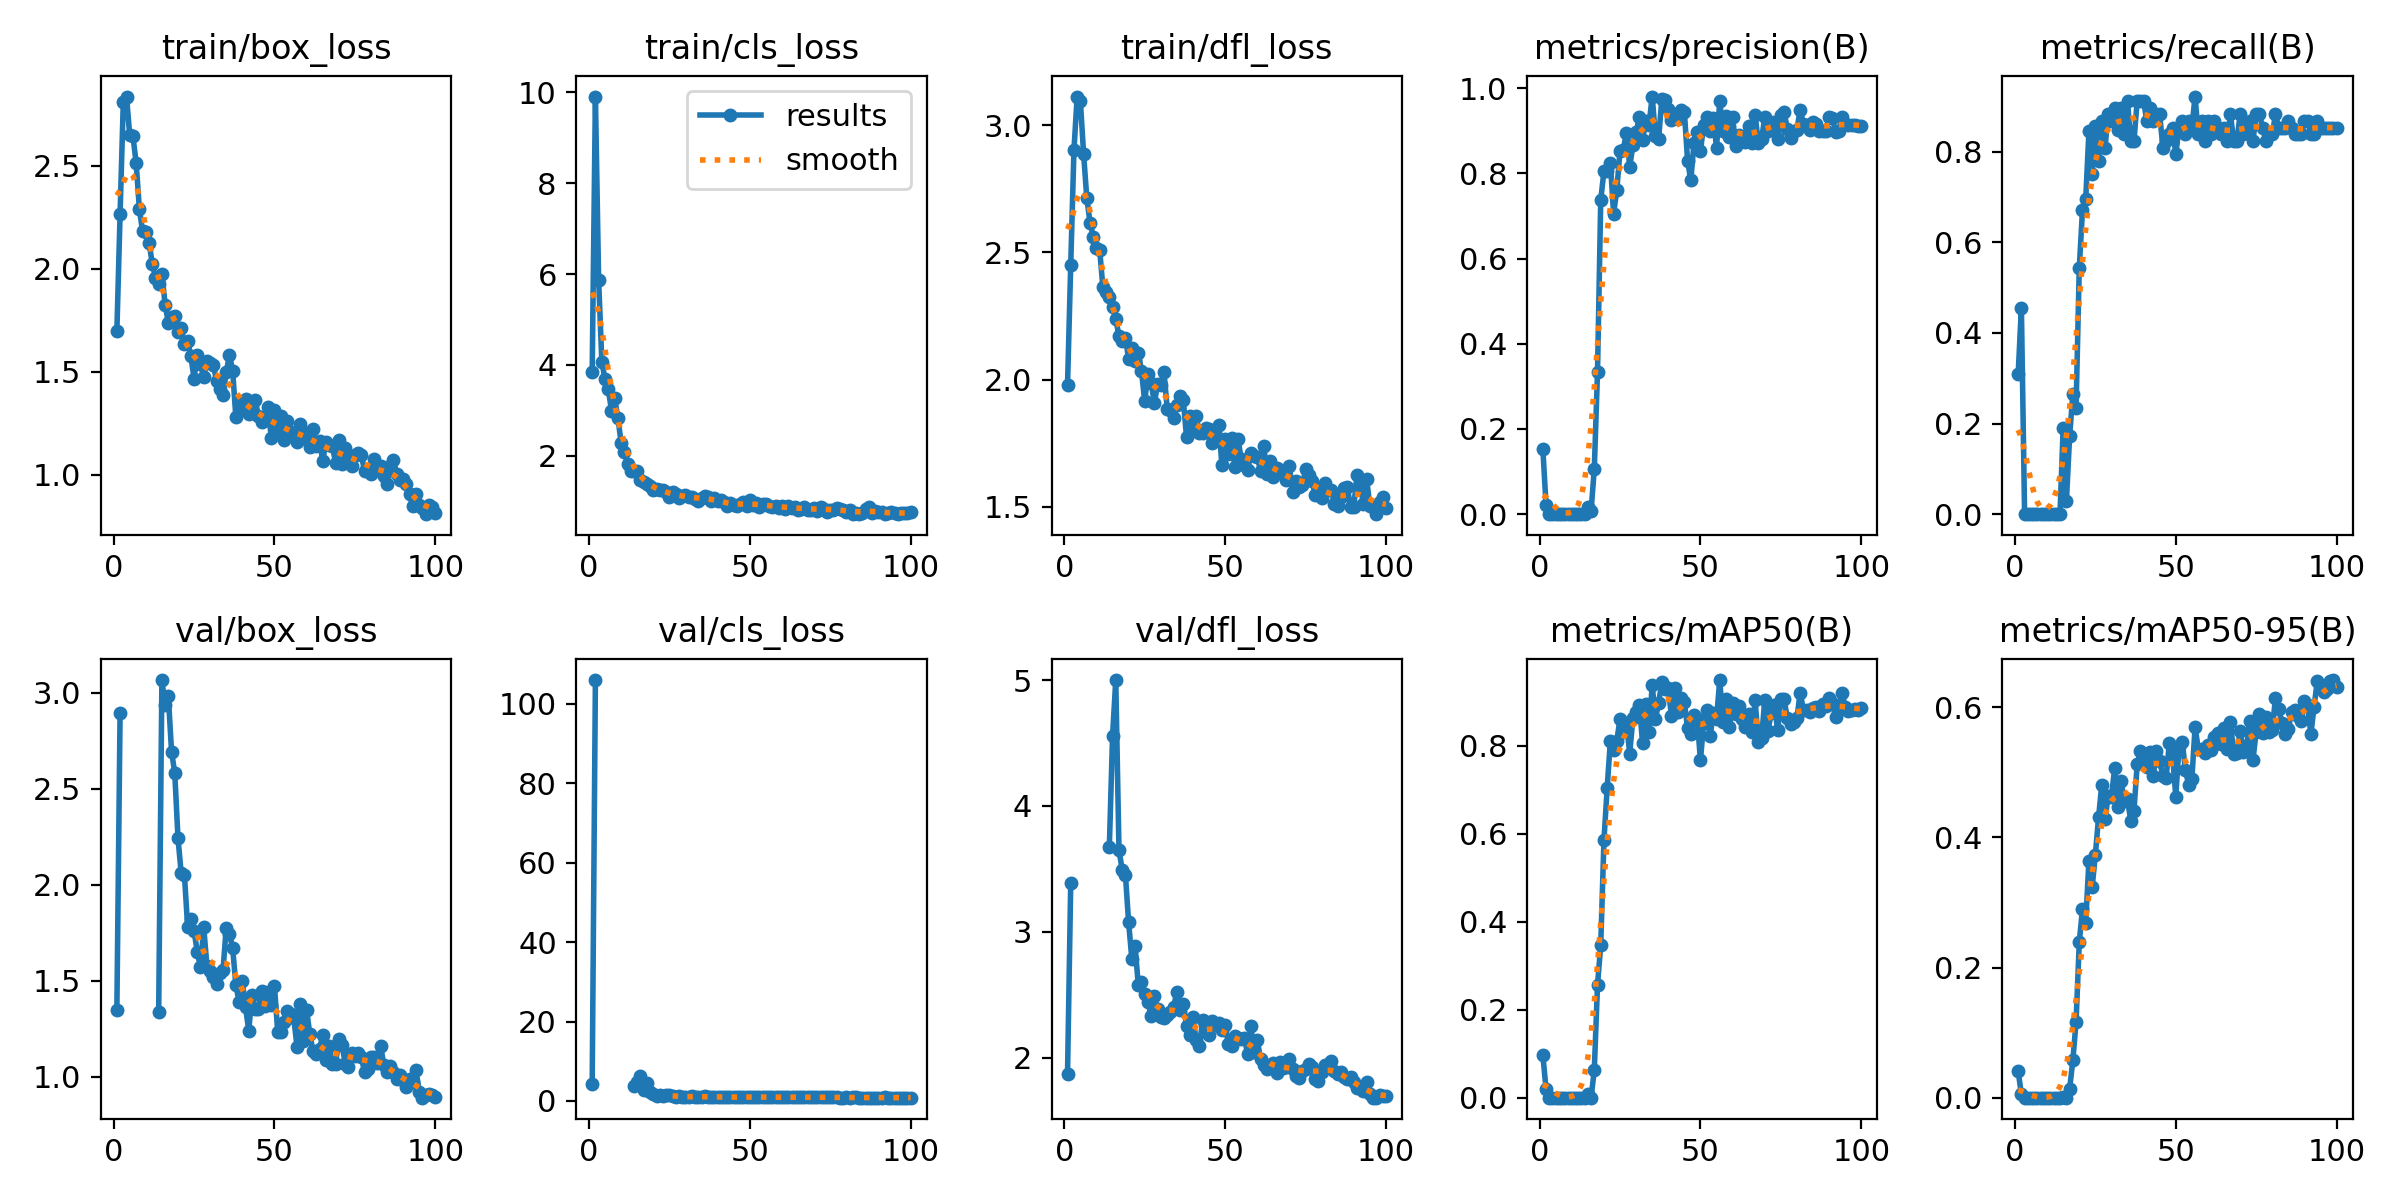

In [ ]:
display(Image(filename=f"{HOME}/runs/detect/train/results.png", width=1000))

In [ ]:
import pandas as pd

results_df = pd.read_csv(f"{HOME}/runs/detect/train/results.csv")
results_df.columns = results_df.columns.str.strip()
results_df.tail()


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
95,96,430.699,0.84046,0.72539,1.49868,0.91474,0.85294,0.87979,0.62329,0.89230,0.82210,1.68300,0.000119,0.000119,0.000119
96,97,434.255,0.80892,0.74496,1.47178,0.91429,0.85294,0.88130,0.62834,0.90422,0.82813,1.68263,0.000099,0.000099,0.000099
97,98,438.628,0.85316,0.74598,1.51933,0.91302,0.85294,0.88339,0.64006,0.91311,0.82833,1.70057,0.000079,0.000079,0.000079
98,99,442.189,0.84517,0.73570,1.53937,0.91178,0.85294,0.88220,0.64205,0.90666,0.83607,1.69886,0.000060,0.000060,0.000060
99,100,445.757,0.81671,0.76356,1.49425,0.91121,0.85294,0.88481,0.63150,0.89718,0.83108,1.69844,0.000040,0.000040,0.000040


### Confusion Matrix

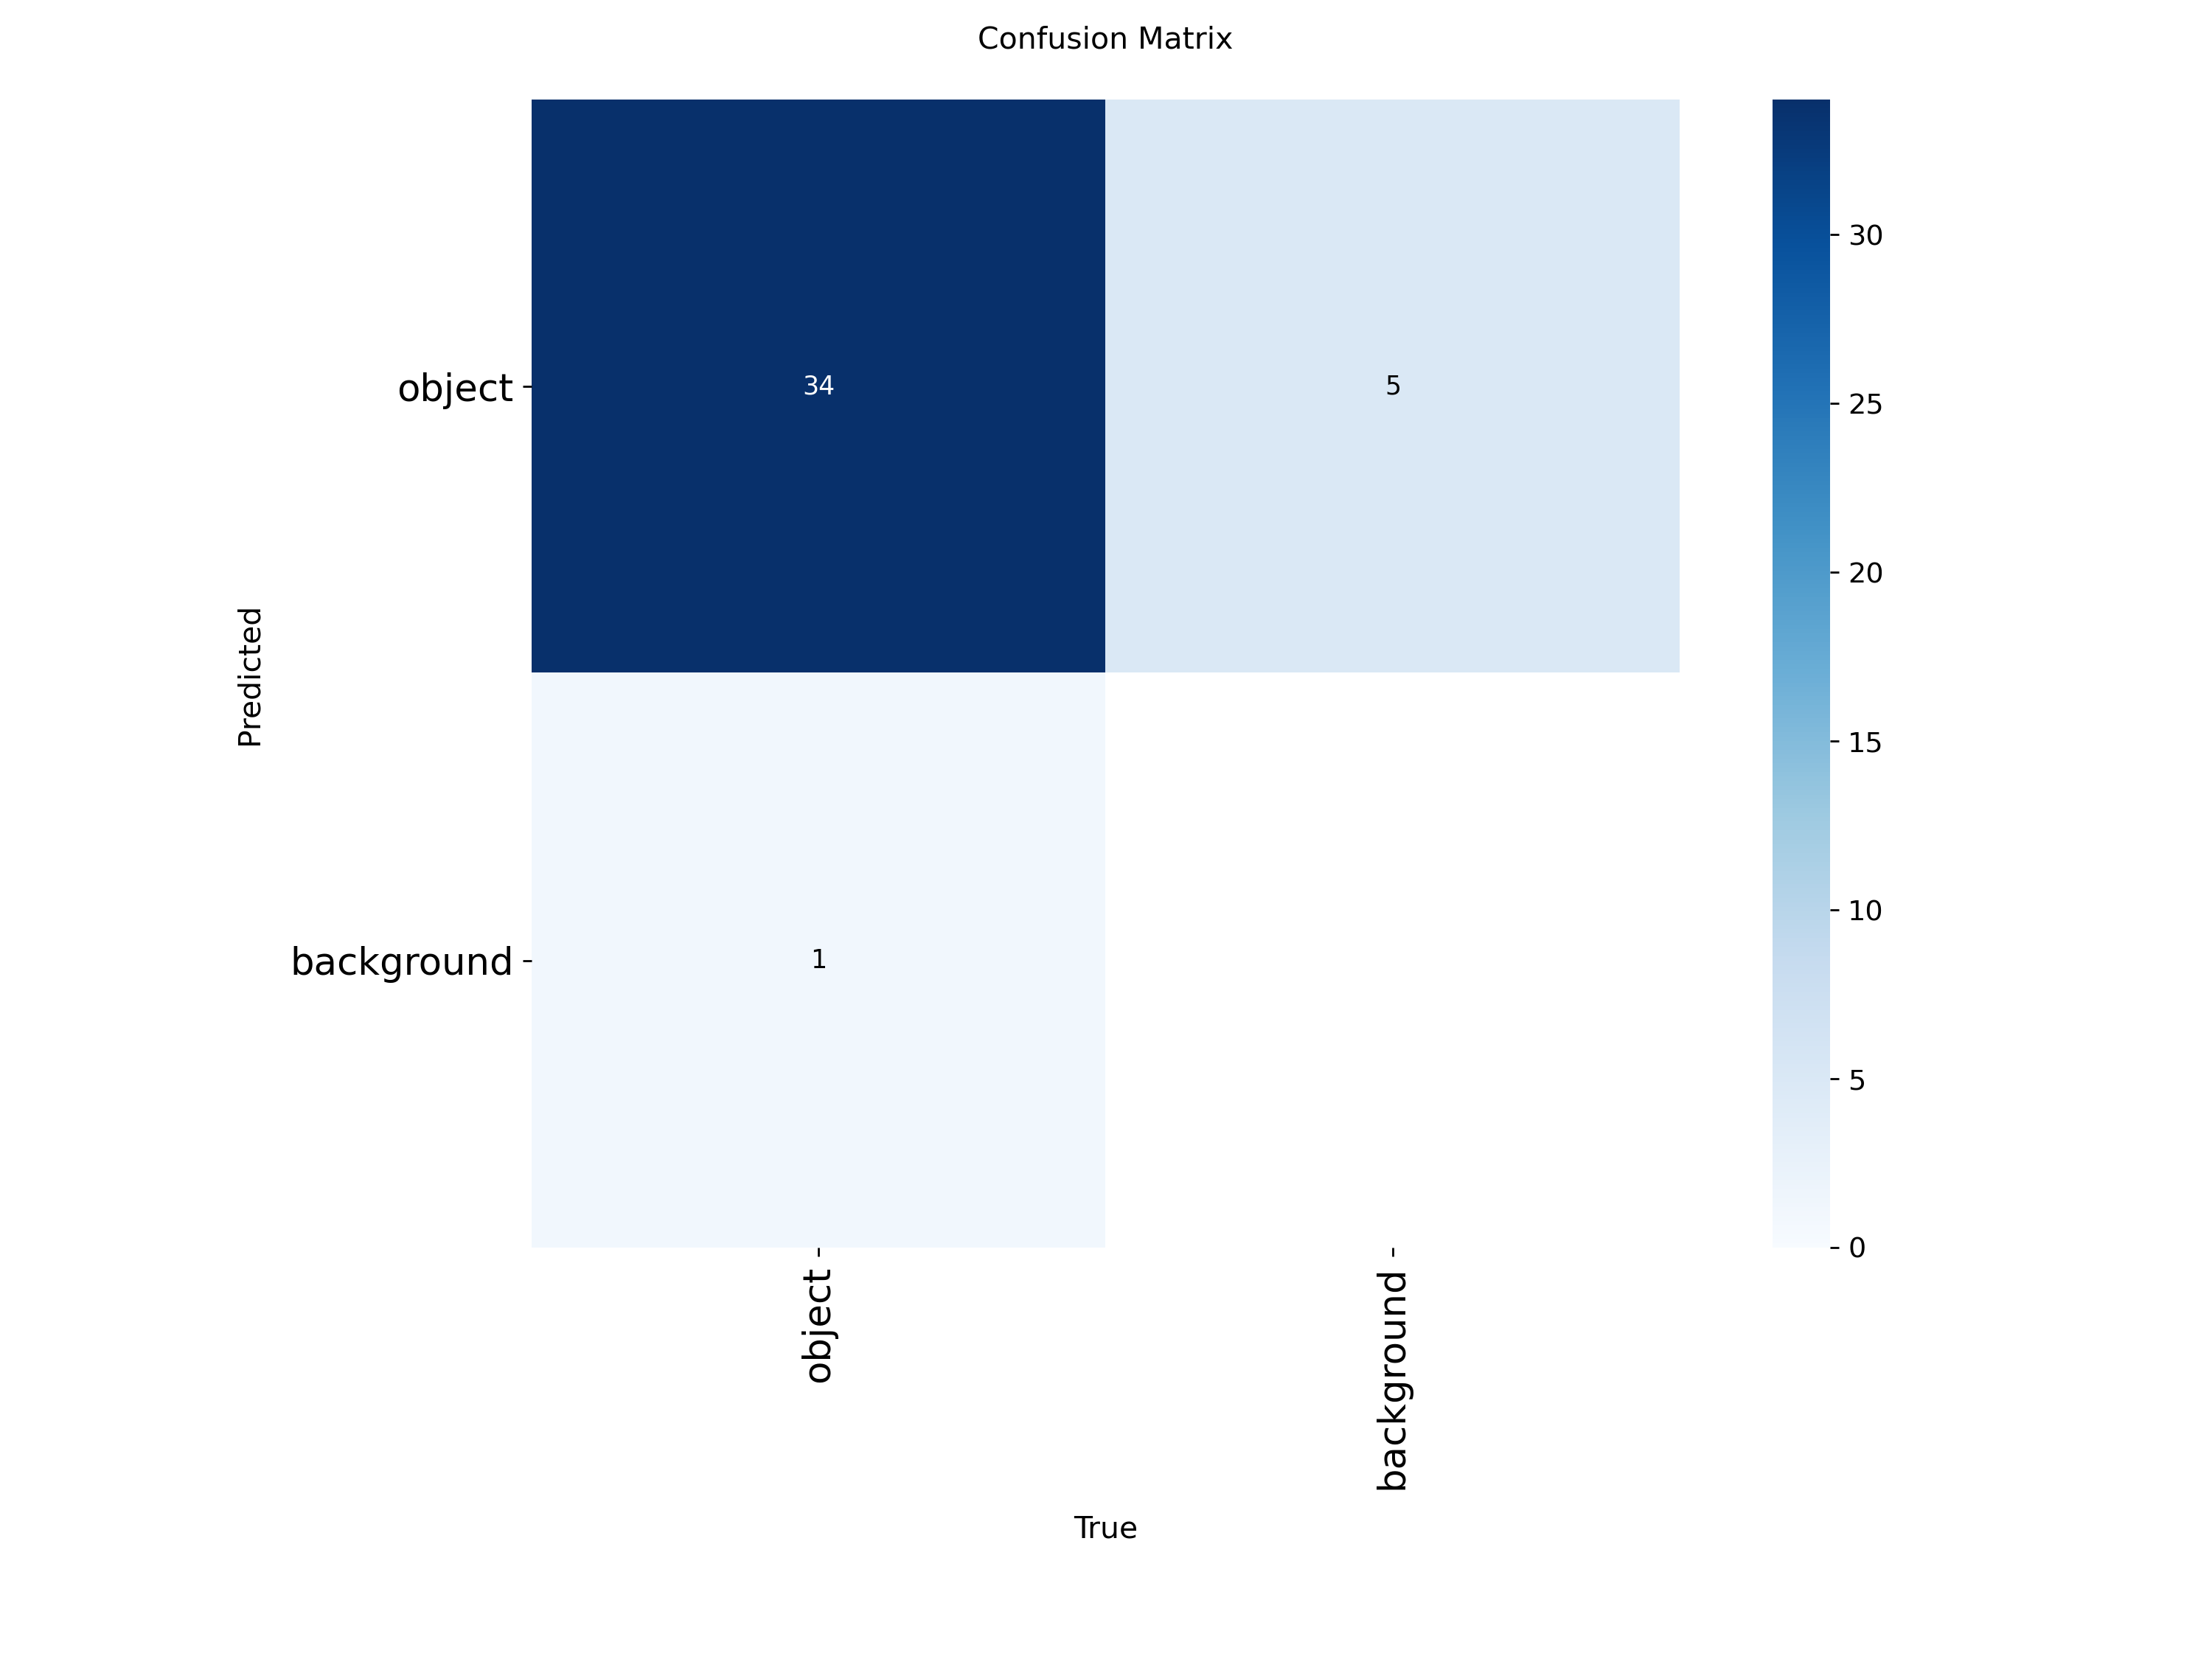

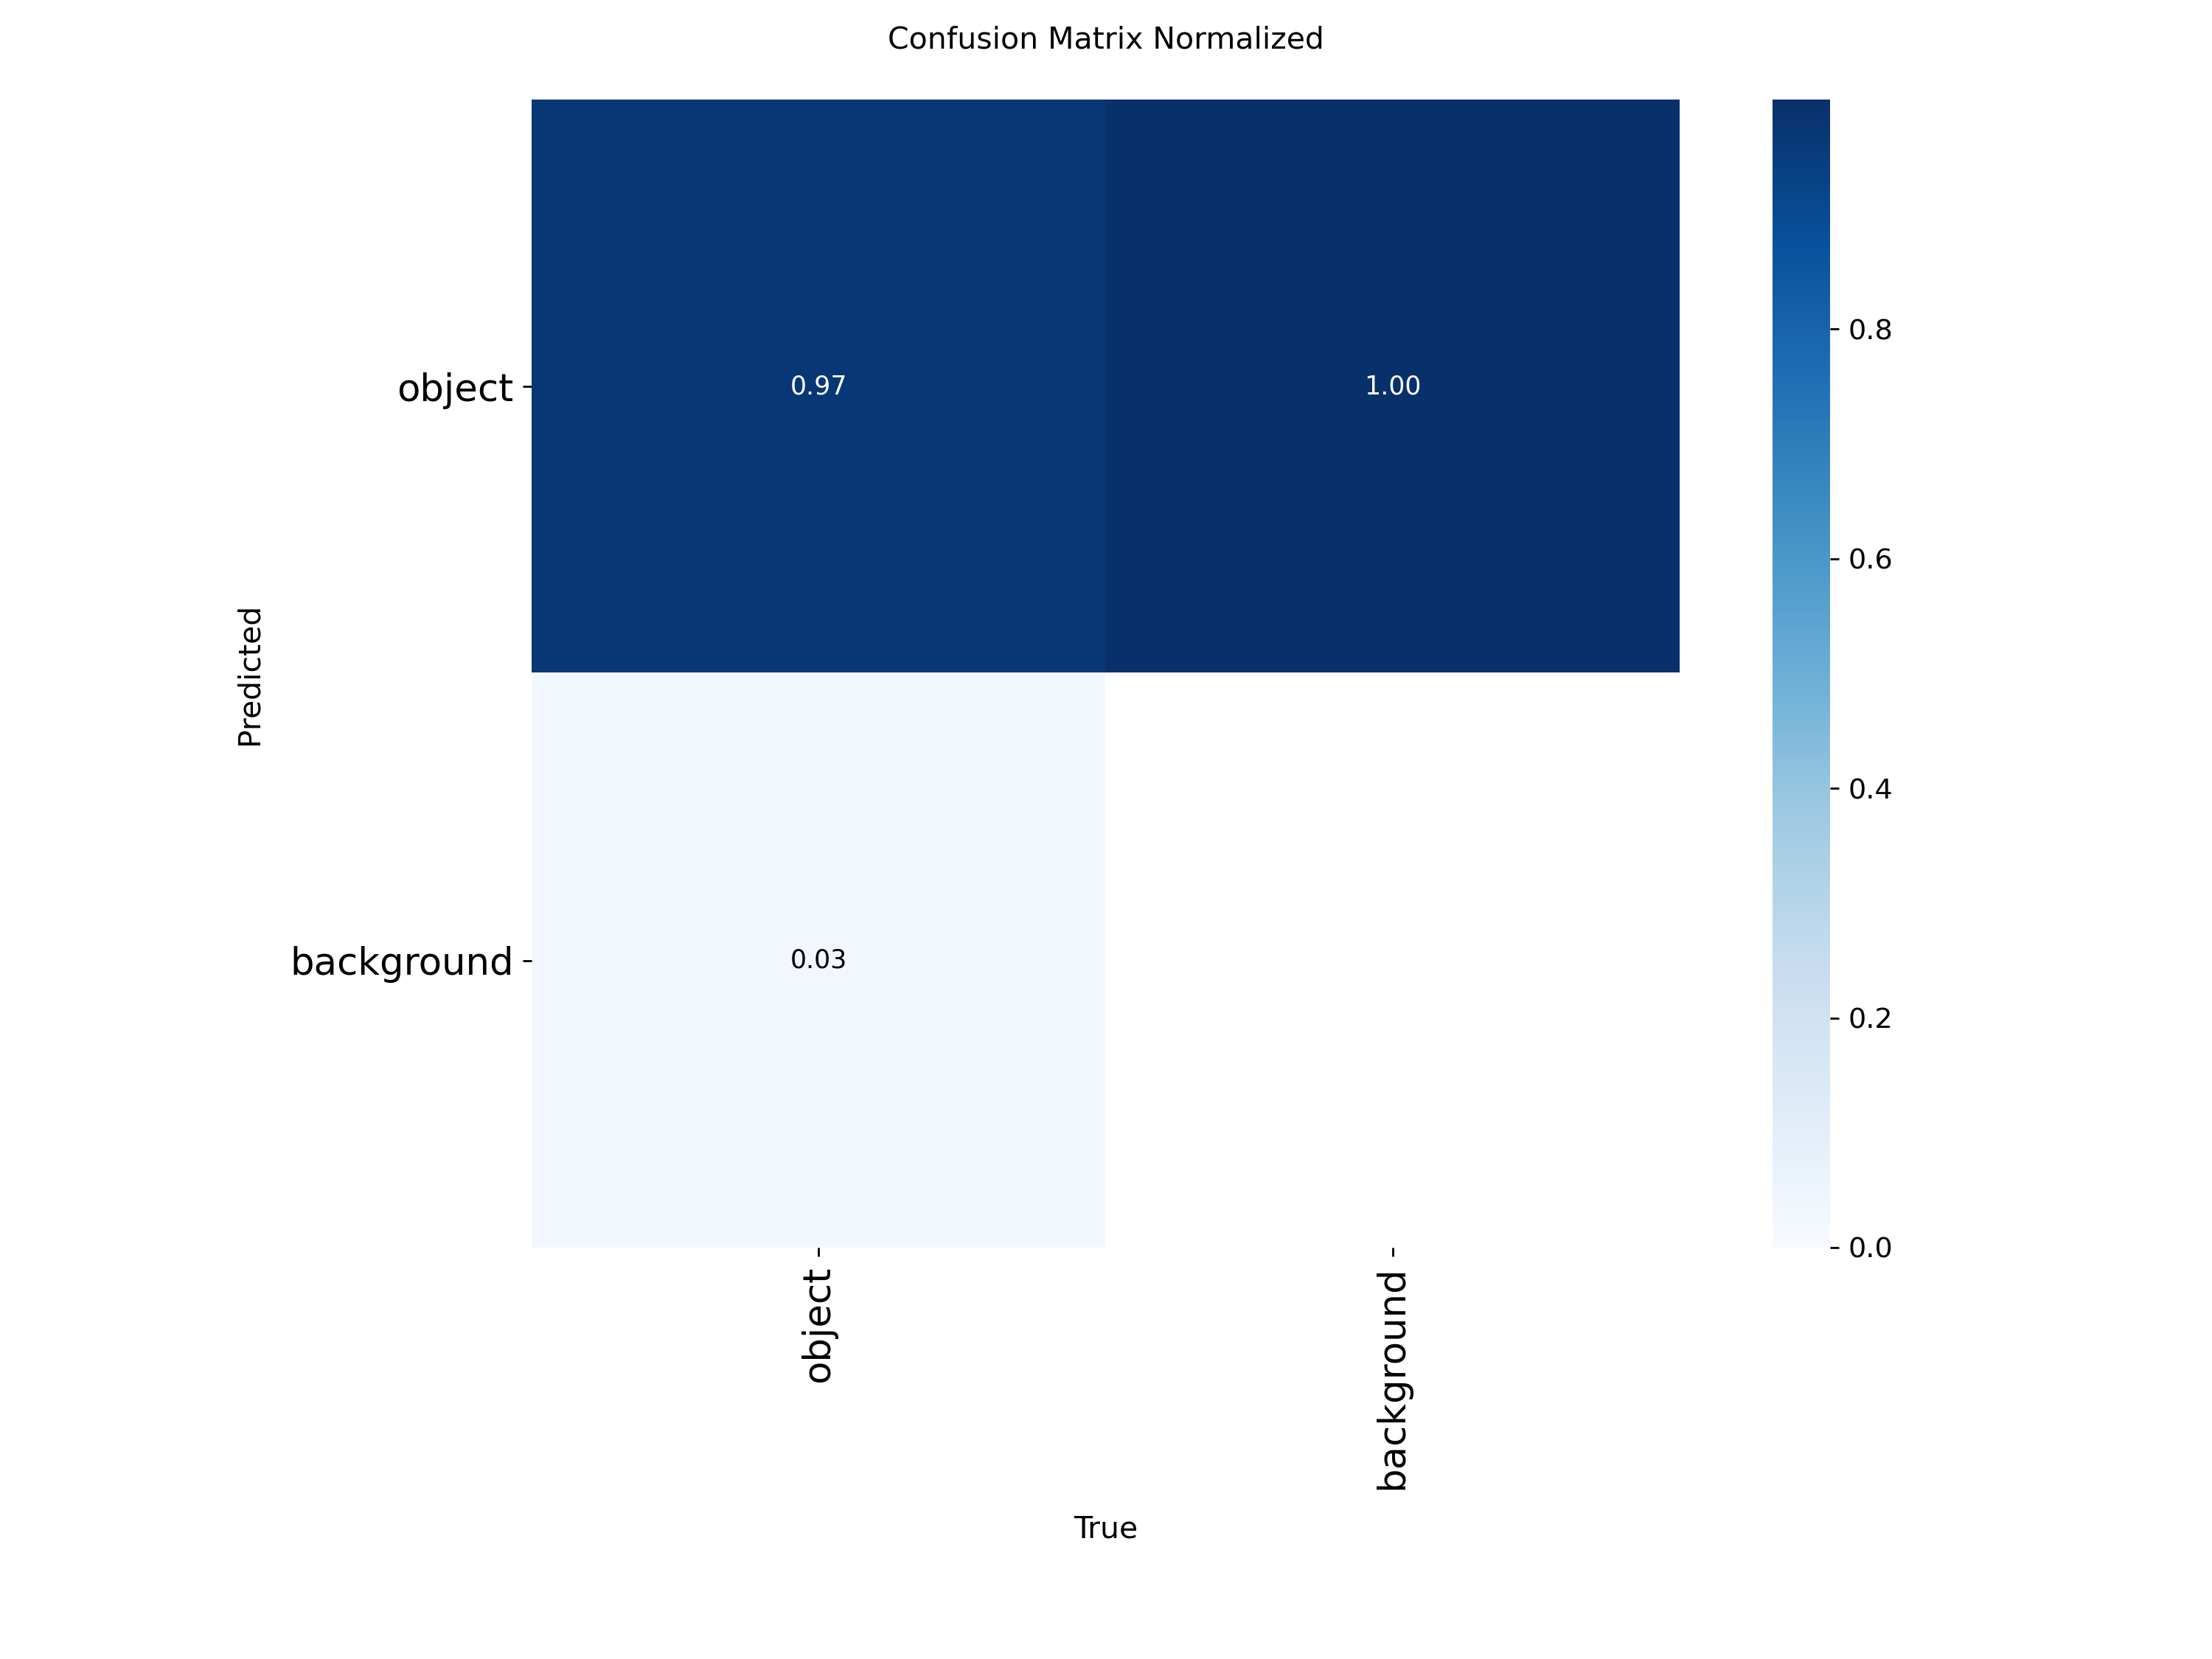

In [ ]:
val_dir = metrics.save_dir  # same directory this validation run actually saved to

display(Image(filename=str(val_dir / "confusion_matrix.png"), width=800))
display(Image(filename=str(val_dir / "confusion_matrix_normalized.png"), width=800))


### F1, Precision, Recall, and Precision-Recall Curves

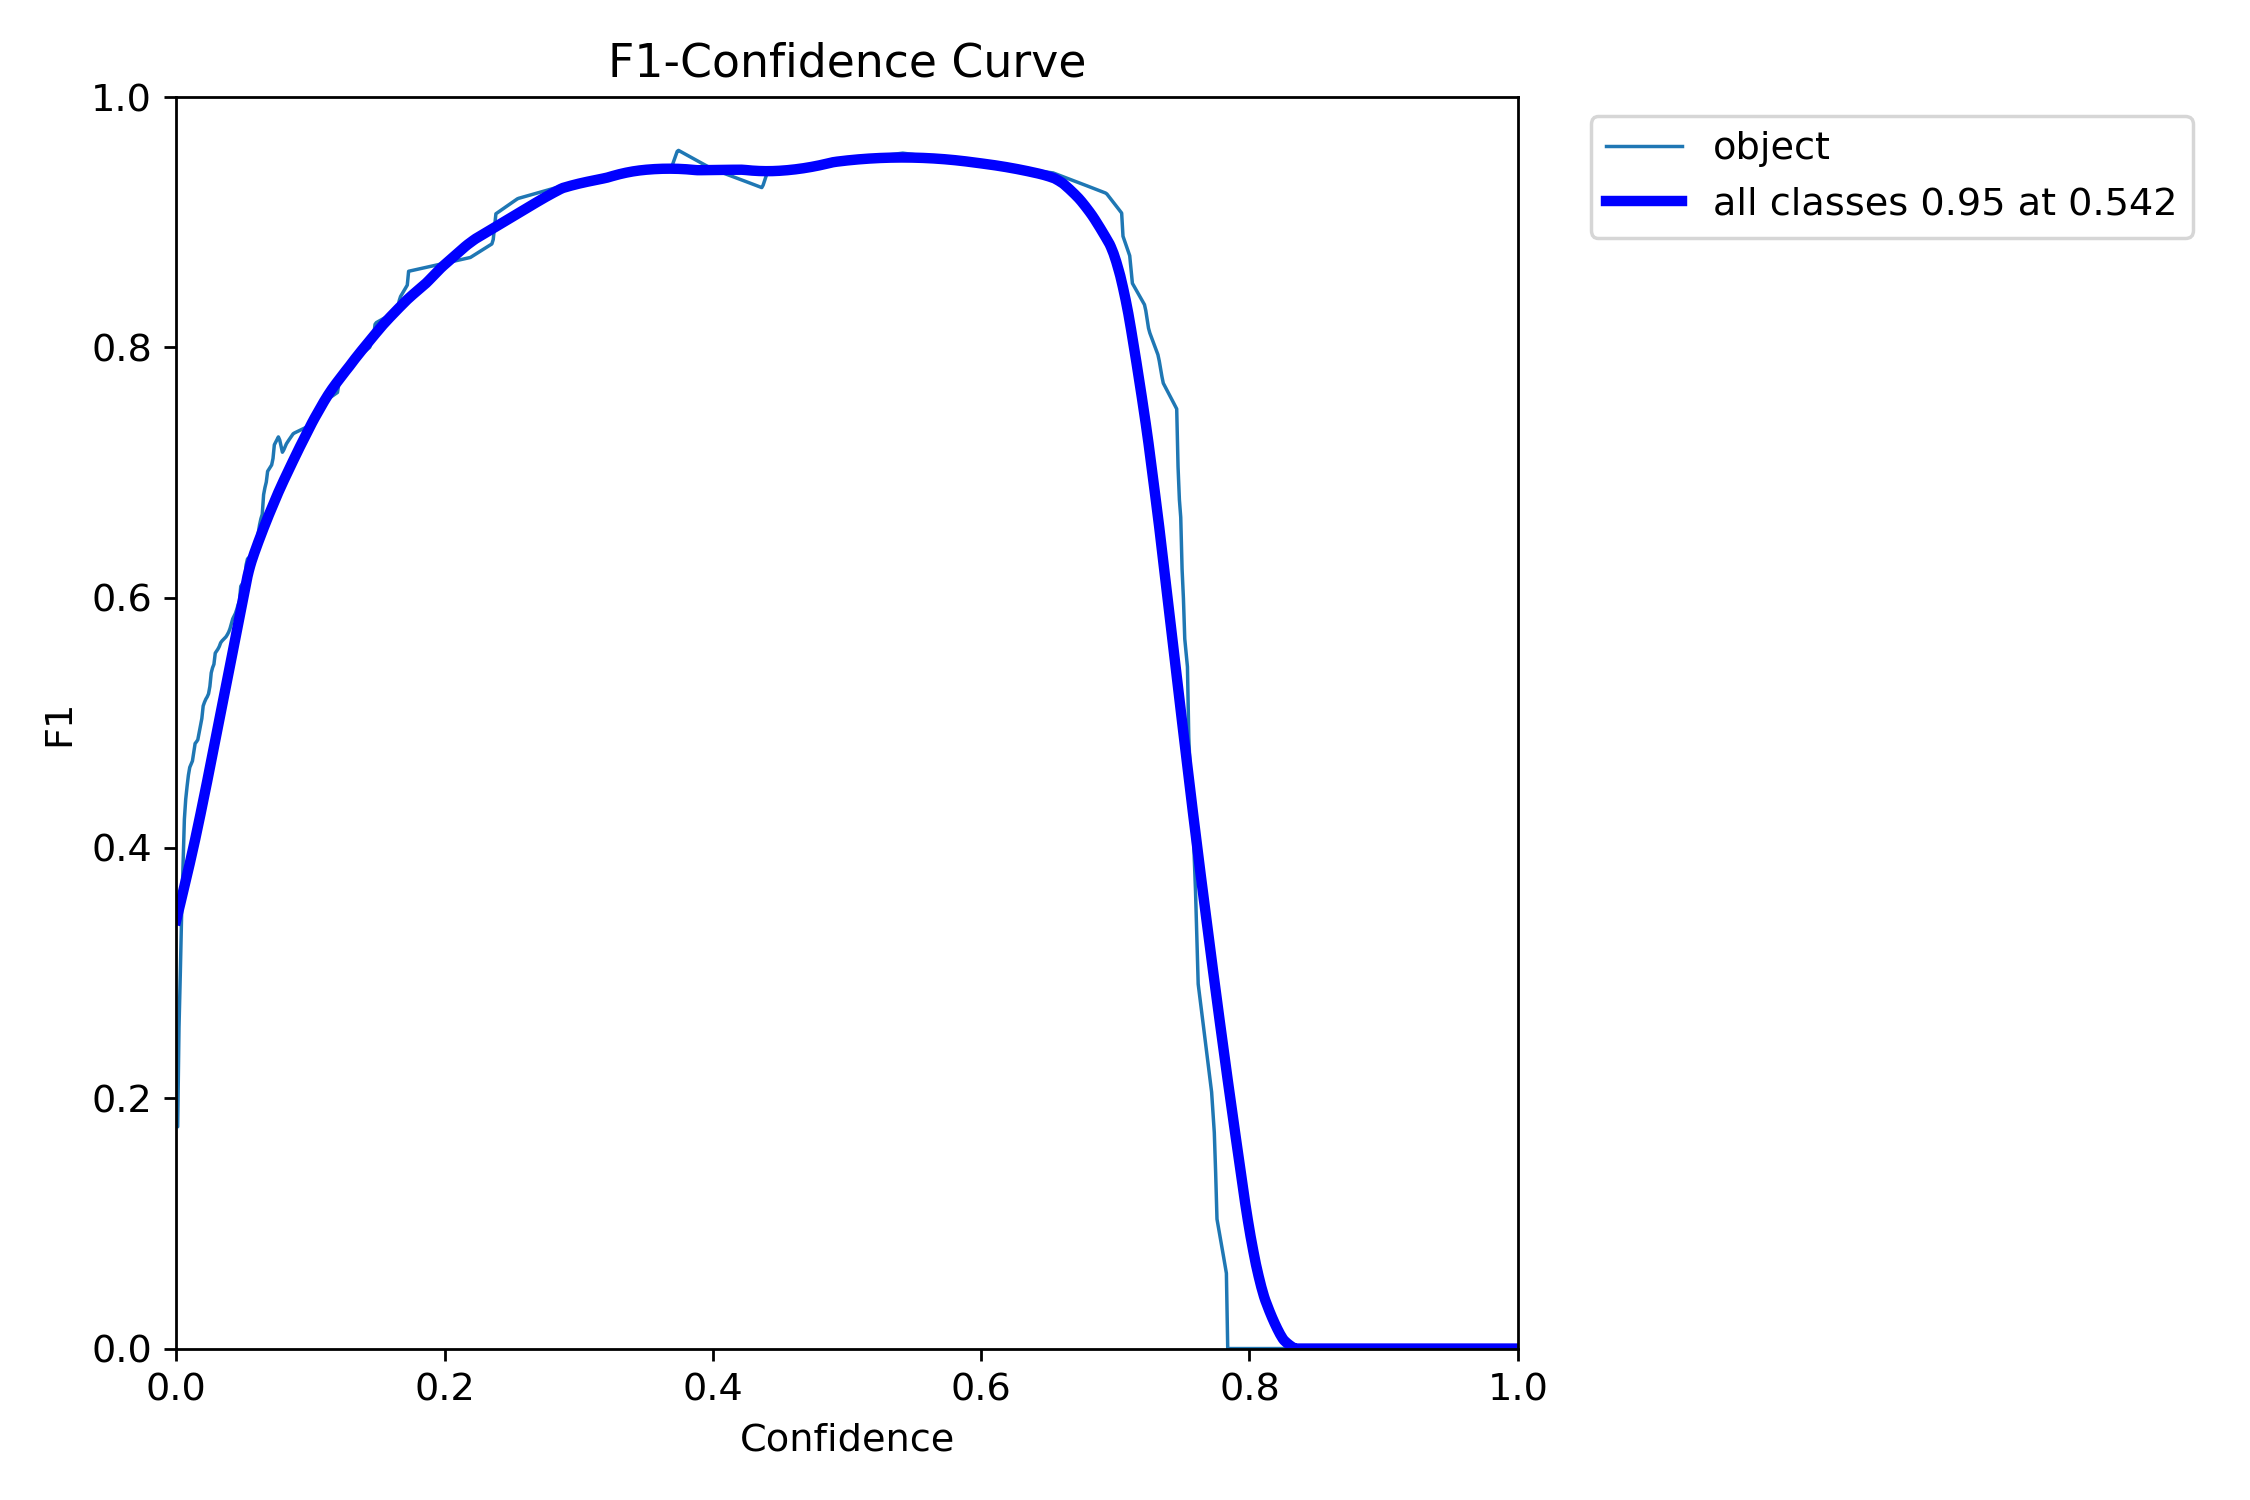

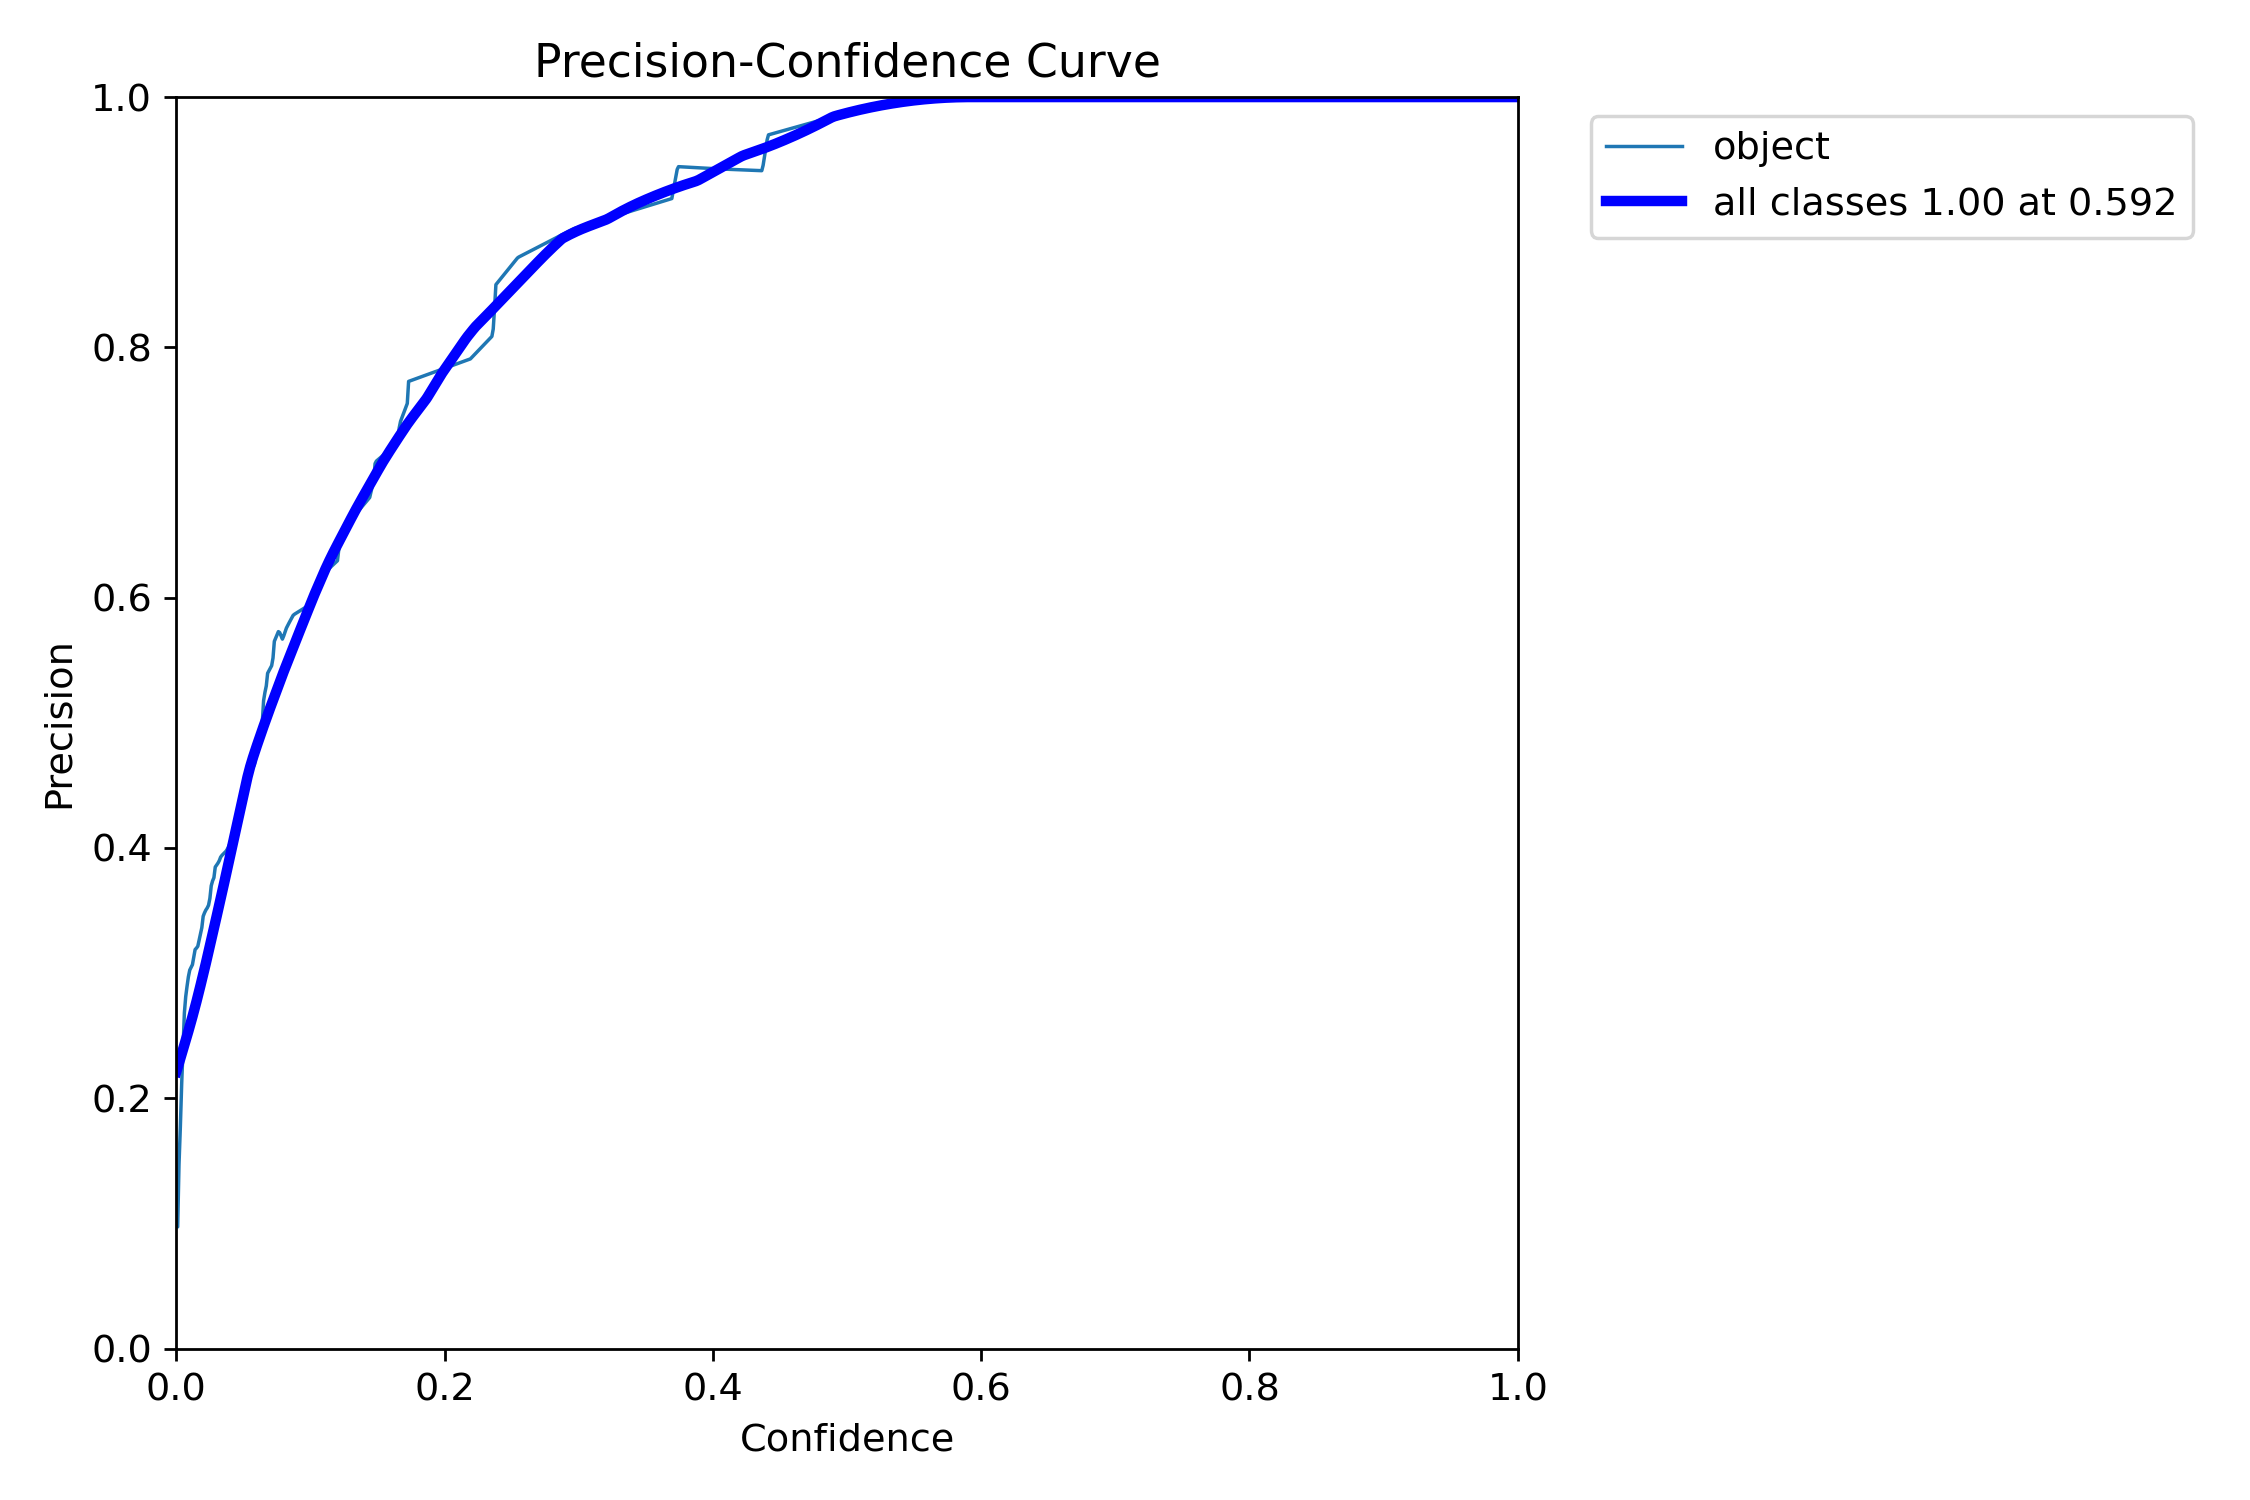

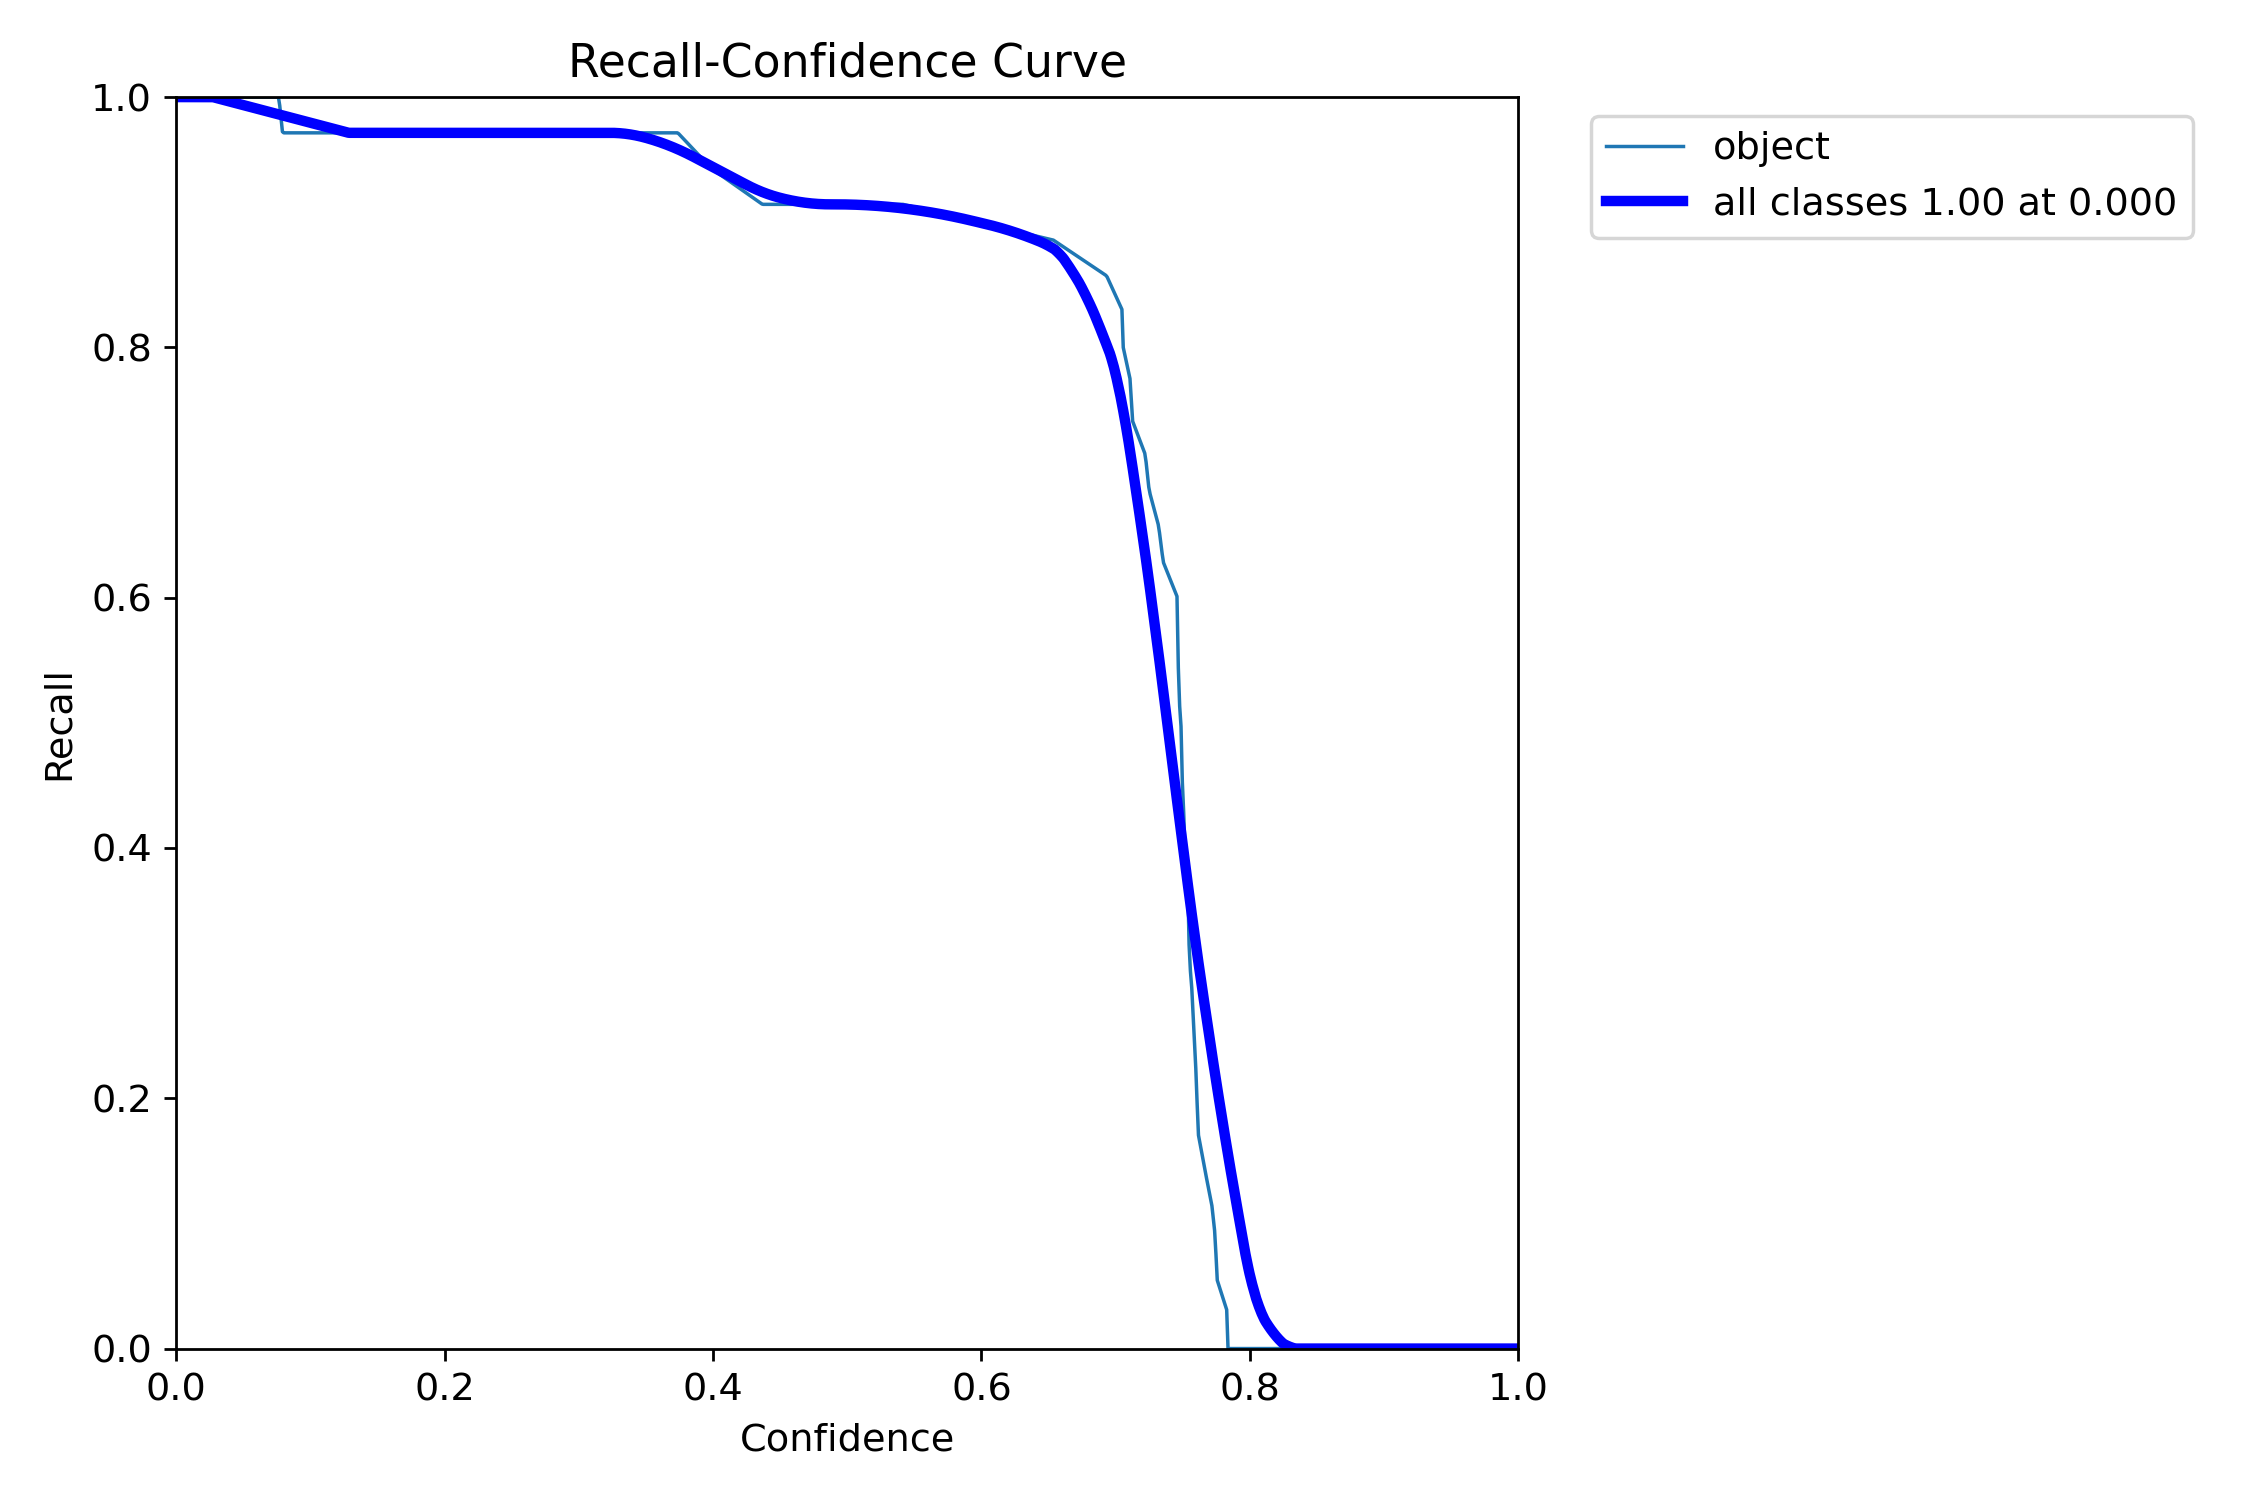

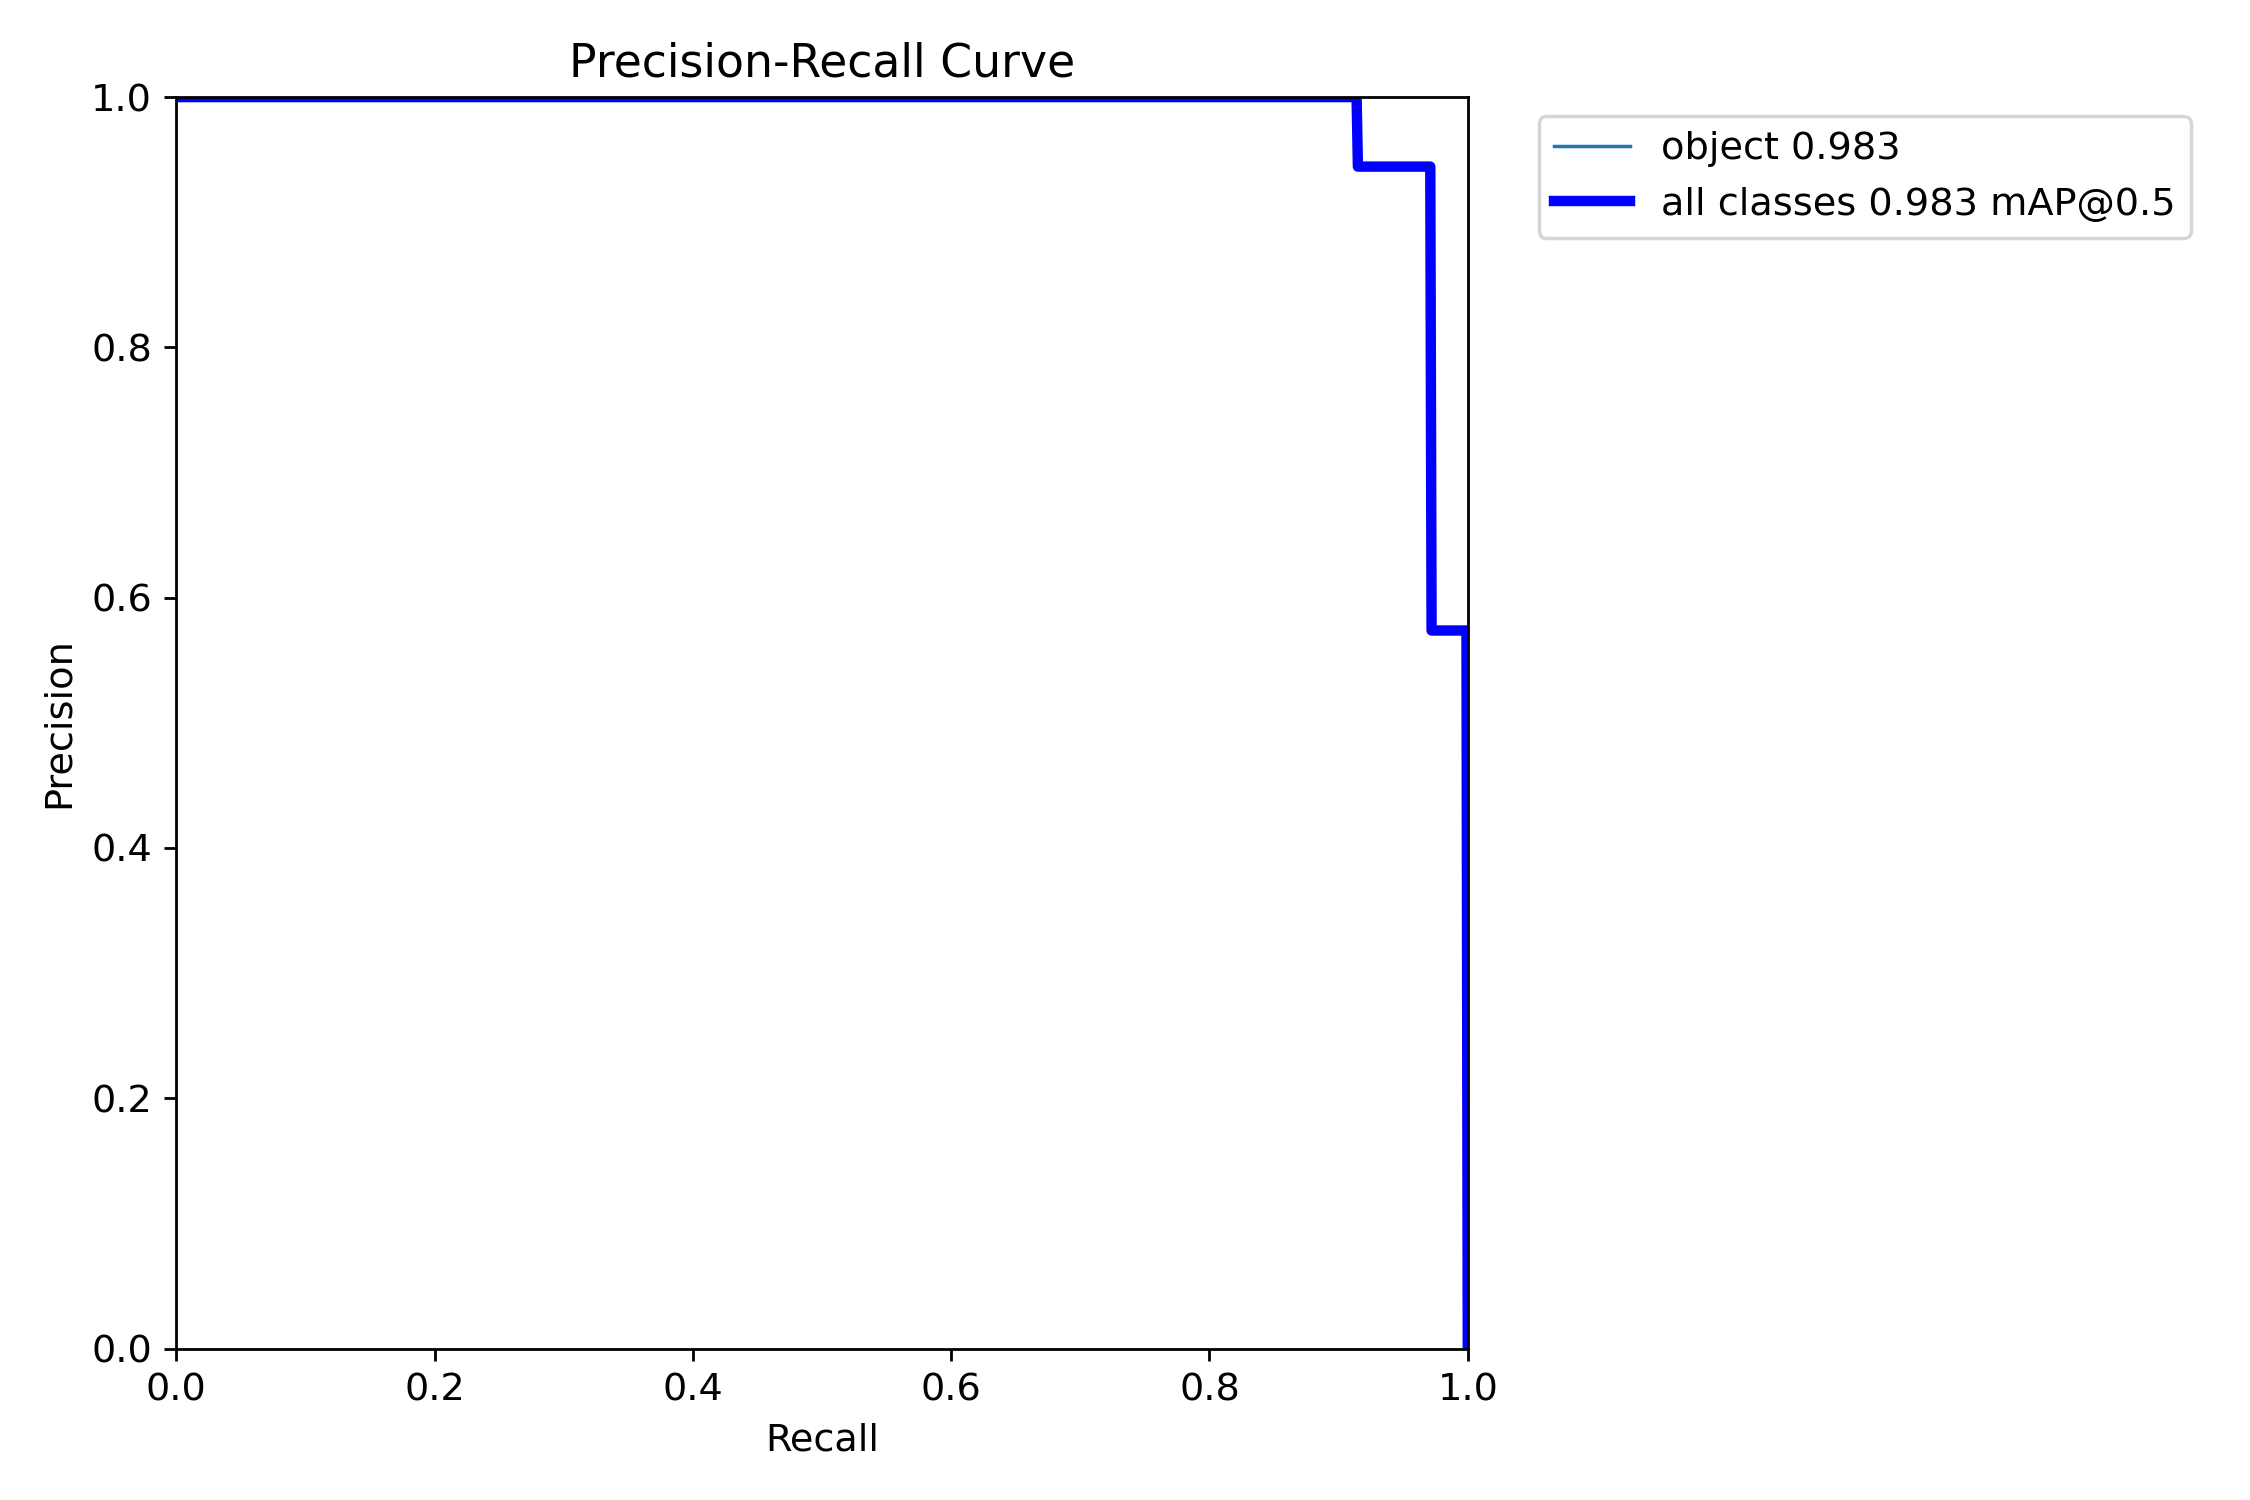

In [ ]:
val_dir = metrics.save_dir  # actual folder this validation run saved to

display(Image(filename=str(val_dir / "BoxF1_curve.png"), width=800))
display(Image(filename=str(val_dir / "BoxP_curve.png"), width=800))
display(Image(filename=str(val_dir / "BoxR_curve.png"), width=800))
display(Image(filename=str(val_dir / "BoxPR_curve.png"), width=800))

### Key Quantitative Metrics (for paper tables)

In [ ]:
print(f"Precision (mean, all classes): {metrics.box.mp:.4f}")
print(f"Recall (mean, all classes):    {metrics.box.mr:.4f}")
print(f"mAP50:                          {metrics.box.map50:.4f}")
print(f"mAP50-95:                       {metrics.box.map:.4f}")

# Per-class breakdown -> useful as a table in the paper
print("\nPer-class metrics:")
print(f"{'Class':<20}{'Precision':>12}{'Recall':>12}{'mAP50':>12}{'mAP50-95':>12}")
for i, c in enumerate(metrics.box.ap_class_index):
    class_name = metrics.names[c]
    p = metrics.box.p[i]
    r = metrics.box.r[i]
    ap50 = metrics.box.ap50[i]
    ap = metrics.box.ap[i]
    print(f"{class_name:<20}{p:>12.4f}{r:>12.4f}{ap50:>12.4f}{ap:>12.4f}")


Precision (mean, all classes): 1.0000
Recall (mean, all classes):    0.9143
mAP50:                          0.9831
mAP50-95:                       0.7197

Per-class metrics:
Class                  Precision      Recall       mAP50    mAP50-95
object                    1.0000      0.9143      0.9831      0.7197


In [ ]:
# Save the per-class table to CSV so it can be dropped straight into the paper
import csv

with open(f"{HOME}/per_class_metrics.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["class", "precision", "recall", "mAP50", "mAP50-95"])
    for i, c in enumerate(metrics.box.ap_class_index):
        writer.writerow([
            metrics.names[c],
            float(metrics.box.p[i]),
            float(metrics.box.r[i]),
            float(metrics.box.ap50[i]),
            float(metrics.box.ap[i]),
        ])

print(f"Saved to {HOME}/per_class_metrics.csv")


Saved to /content/per_class_metrics.csv


In [ ]:
import glob
for f in glob.glob("/content/runs/detect/*/weights/best.pt"):
    print(f)

/content/runs/detect/train/weights/best.pt


### A note on ROC / AUC curves

I'm not adding a ROC/AUC curve as a standard output here, and want to be upfront about why rather than generate something misleading.

ROC-AUC is a **binary classification** metric (true positive rate vs. false positive rate at varying thresholds, over a fixed set of positive/negative samples). Object detection doesn't have that structure — the number of objects per image is variable, "negatives" aren't well-defined the way they are in classification, and predictions depend on both classification confidence *and* localization (IoU) accuracy. Because of this, **Ultralytics/YOLO does not compute or output a ROC/AUC curve for detection**, and it isn't standard practice in the object-detection literature.

The metrics detection papers actually report in place of ROC-AUC are exactly what's generated above:
- **Precision-Recall (PR) curve** — the direct analog of ROC for detection
- **mAP@0.5** and **mAP@0.5:0.95** — the standard headline metrics
- **F1 curve** — F1 score vs. confidence threshold
- **Confusion matrix** — class-wise TP/FP/FN breakdown

If a reviewer or your paper's format specifically requires a ROC/AUC-style curve anyway, it's possible to approximate one by treating each class as one-vs-rest at the image or box level and sweeping the confidence threshold to compute TPR/FPR manually — but this requires assumptions about what counts as a "negative" and is non-standard, so I'd rather flag that limitation than fabricate one. Let me know if you want that approximation built out and I'll do it explicitly with the assumptions stated.

## Ablation Study

This section runs controlled ablations on top of the baseline `yolo12s` model trained above, to isolate the contribution of three factors:

1. **Model capacity** — `yolo12n` (nano) vs. `yolo12s` (baseline, already trained above) vs. `yolo12m` (medium)
2. **Data augmentation** — baseline augmentation vs. mosaic disabled vs. all augmentation disabled
3. **Input resolution** — 416 vs. 640 (baseline) vs. 832

Every variant trains from the same pretrained checkpoint family, on the same `data.yaml` (the same train/valid/test split Roboflow created), and is evaluated exactly like the baseline above (`model.val(data=DATA_YAML, split="test")`), so the comparison is apples-to-apples.

**Compute note:** this trains several additional full models. On the free-tier T4 used above, the baseline `yolo12s` run took most of a session for 100 epochs on this ~134-image train set. Running every variant below at the same 100 epochs will roughly multiply that by the number of configs. If you're time/compute constrained, lower `ABLATION_EPOCHS` below (e.g. to 50) — just keep it identical across every config so the comparison stays fair, and state that reduced budget when you report results.

In [ ]:
import time
import torch
import pandas as pd

ABLATION_EPOCHS = 100  # keep identical across every config below for a fair comparison;
                        # lower this (e.g. to 50) if you are compute/time constrained

def train_and_evaluate(config, project_dir=f"{HOME}/runs/ablation"):
    """
    Train one ablation variant and evaluate it exactly like the baseline model above
    (validation on the held-out 'test' split of the same data.yaml).
    Does not touch the baseline `best_model` / `metrics` variables from earlier cells.
    """
    cfg = dict(config)
    run_name = cfg.pop("name")
    model_weights = cfg.pop("model", "yolo12s.pt")

    t0 = time.time()
    variant_model = YOLO(model_weights)
    variant_model.train(
        data=DATA_YAML,
        project=project_dir,
        name=run_name,
        exist_ok=True,
        verbose=False,  # suppress per-epoch tables; remove this line for full training logs
        **cfg,
    )
    elapsed = time.time() - t0

    best_pt = f"{project_dir}/{run_name}/weights/best.pt"
    eval_model = YOLO(best_pt)
    m = eval_model.val(data=DATA_YAML, split="test", plots=False)

    result = {
        "config_name": run_name,
        "precision": float(m.box.mp),
        "recall": float(m.box.mr),
        "mAP50": float(m.box.map50),
        "mAP50-95": float(m.box.map),
        "train_time_s": round(elapsed, 1),
        "weights_path": best_pt,
    }

    del variant_model, eval_model
    torch.cuda.empty_cache()
    return result


ablation_configs = [
    # --- Model capacity ---
    {"name": "scale_yolo12n", "model": "yolo12n.pt", "epochs": ABLATION_EPOCHS, "imgsz": 640},
    {"name": "scale_yolo12m", "model": "yolo12m.pt", "epochs": ABLATION_EPOCHS, "imgsz": 640},

    # --- Data augmentation ---
    {"name": "aug_no_mosaic", "model": "yolo12s.pt", "epochs": ABLATION_EPOCHS, "imgsz": 640,
     "mosaic": 0.0},
    {"name": "aug_none", "model": "yolo12s.pt", "epochs": ABLATION_EPOCHS, "imgsz": 640,
     "mosaic": 0.0, "hsv_h": 0.0, "hsv_s": 0.0, "hsv_v": 0.0,
     "fliplr": 0.0, "flipud": 0.0, "degrees": 0.0, "translate": 0.0,
     "scale": 0.0, "shear": 0.0, "perspective": 0.0, "erasing": 0.0},

    # --- Input resolution ---
    {"name": "res_416", "model": "yolo12s.pt", "epochs": ABLATION_EPOCHS, "imgsz": 416},
    {"name": "res_832", "model": "yolo12s.pt", "epochs": ABLATION_EPOCHS, "imgsz": 832},
]

ablation_rows = [train_and_evaluate(cfg) for cfg in ablation_configs]

# Baseline row reuses the `metrics` object already computed above on the same test split,
# from the exact yolo12s / imgsz=640 / default-augmentation / 100-epoch run -> no retraining.
baseline_row = {
    "config_name": "baseline_yolo12s (main run above)",
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50-95": float(metrics.box.map),
    "train_time_s": None,
    "weights_path": f"{HOME}/runs/detect/train/weights/best.pt",
}

ablation_df = pd.DataFrame([baseline_row] + ablation_rows)
ablation_df.to_csv(f"{HOME}/ablation_results.csv", index=False)
ablation_df

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/object-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=scale_yolo12n, nbs=64, nms=None, opset=N

,config_name,precision,recall,mAP50,mAP50-95,train_time_s,weights_path
0,baseline_yolo12s (main run above),1.000000,0.914280,0.983142,0.719682,NaN,/content/runs/detect/train/weights/best.pt
1,scale_yolo12n,0.962835,0.885714,0.968108,0.717021,369.8,/content/runs/ablation/scale_yolo12n/weights/b...
2,scale_yolo12m,0.990862,0.942857,0.982013,0.712592,1278.4,/content/runs/ablation/scale_yolo12m/weights/b...
3,aug_no_mosaic,0.998533,0.914286,0.983057,0.752449,431.5,/content/runs/ablation/aug_no_mosaic/weights/b...
4,aug_none,0.932009,0.914286,0.951995,0.590713,420.2,/content/runs/ablation/aug_none/weights/best.pt
5,res_416,1.000000,0.937812,0.989234,0.748668,379.4,/content/runs/ablation/res_416/weights/best.pt
6,res_832,0.992772,0.942857,0.984809,0.717410,936.3,/content/runs/ablation/res_832/weights/best.pt


set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


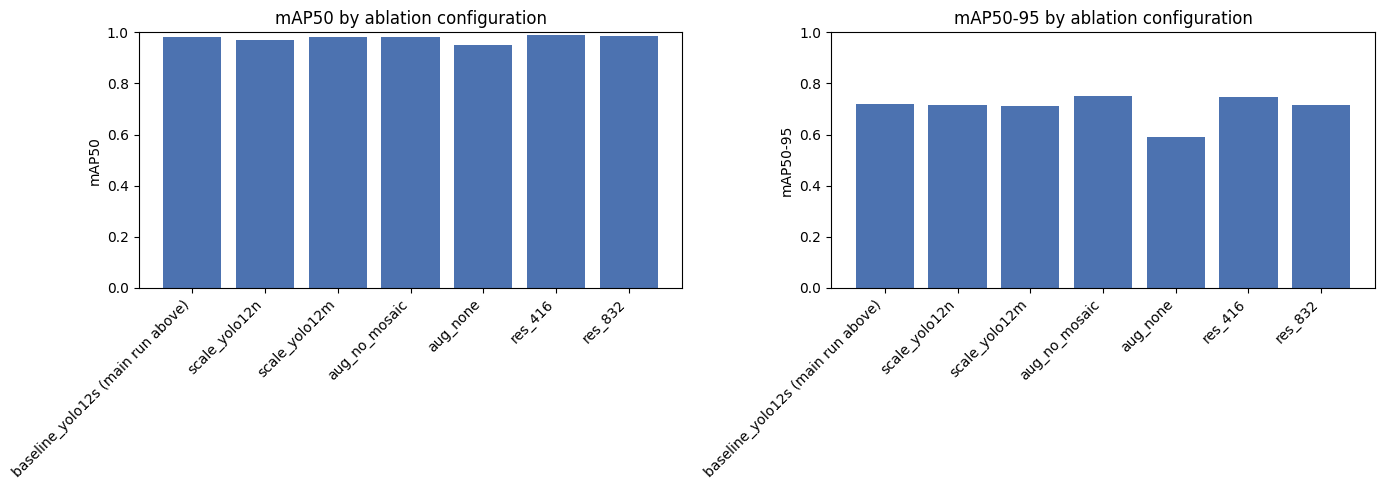

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ["mAP50", "mAP50-95"]):
    ax.bar(ablation_df["config_name"], ablation_df[col], color="#4C72B0")
    ax.set_ylabel(col)
    ax.set_title(f"{col} by ablation configuration")
    ax.set_xticklabels(ablation_df["config_name"], rotation=45, ha="right")
    ax.set_ylim(0, 1.0)

plt.tight_layout()
plt.savefig(f"{HOME}/ablation_comparison.png", dpi=150)
plt.show()